# SIFT matching and geometric verification

Which descriptor matches survive a known geometric transformation?

The project separates appearance matching from geometry. I compare Lowe's ratio threshold, estimate a homography with RANSAC and inspect its inliers.

## Run settings

The default run uses CPU and a small training budget. Set `PROJECT_FULL=1` before opening the notebook for the longer run. Both modes use the same data split and evaluation code. A short run checks the experiment; the number of epochs limits what its scores can establish.

In [3]:
import json
import os
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

root = Path.cwd()
while not (root / "pyproject.toml").exists() and root != root.parent:
    root = root.parent
if not (root / "pyproject.toml").exists():
    raise FileNotFoundError("Open this notebook inside the repository")
sys.path.insert(0, str(root / "src"))
from vision_projects.training import seed_everything

QUICK = os.environ.get("PROJECT_FULL", "0") != "1"
EPOCHS = 6 if QUICK else 40
seed_everything(1031)
output = root / "figures" / "02_sift_and_geometry"
output.mkdir(parents=True, exist_ok=True)
(root / "results").mkdir(exist_ok=True)
print({"torch": torch.__version__, "device": "cpu", "epochs": EPOCHS, "seed": 1031})

{'torch': '2.14.1+cu130', 'device': 'cpu', 'epochs': 40, 'seed': 1031}


## A controlled image pair

A known projective warp of the camera image provides ground-truth geometry. Mountain images from the archive can be used afterward, but their correspondence errors lack a supplied ground-truth homography.

In [5]:
import cv2
from skimage import data as sample_images

image = sample_images.camera()
expected = np.array(
    [[0.95, -0.06, 25], [0.04, 0.98, 8], [0.00008, -0.00005, 1]], dtype=np.float64
)
warped = cv2.warpPerspective(image, expected, (image.shape[1], image.shape[0]))
sift = cv2.SIFT_create(nfeatures=900)
keypoints_a, descriptors_a = sift.detectAndCompute(image, None)
keypoints_b, descriptors_b = sift.detectAndCompute(warped, None)
print(len(keypoints_a), len(keypoints_b), descriptors_a.shape)

791 847 (791, 128)


## Descriptor ambiguity

For each query descriptor, the two closest candidates are compared. A ratio near one indicates ambiguity. Distance alone cannot distinguish a good repeated texture from a unique feature.

In [7]:
matcher = cv2.BFMatcher(cv2.NORM_L2)
neighbors = matcher.knnMatch(descriptors_a, descriptors_b, k=2)
rows = []
for ratio in [0.6, 0.7, 0.8, 0.9]:
    matches = [
        first for first, second in neighbors if first.distance < ratio * second.distance
    ]
    points_a = np.float32([keypoints_a[m.queryIdx].pt for m in matches])
    points_b = np.float32([keypoints_b[m.trainIdx].pt for m in matches])
    transformed = cv2.perspectiveTransform(points_a[:, None], expected)[:, 0]
    errors = np.linalg.norm(transformed - points_b, axis=1)
    rows.append(
        {
            "ratio": ratio,
            "matches": len(matches),
            "precision_within_3px": float(np.mean(errors < 3)),
        }
    )
print(pd.DataFrame(rows))

   ratio  matches  precision_within_3px
0    0.6      425              0.995294
1    0.7      442              0.988688
2    0.8      462              0.971861
3    0.9      530              0.862264


## RANSAC homography

RANSAC fits $\mathbf{x}' \sim H\mathbf{x}$ using small subsets, then counts correspondences within a reprojection threshold. At least four non-collinear matches are required. I fix the ratio at 0.7 before estimating geometry.

In [9]:
matches = [
    first for first, second in neighbors if first.distance < 0.7 * second.distance
]
if len(matches) < 4:
    raise ValueError("Homography requires at least four matches")
points_a = np.float32([keypoints_a[m.queryIdx].pt for m in matches])
points_b = np.float32([keypoints_b[m.trainIdx].pt for m in matches])
estimated, mask = cv2.findHomography(points_a, points_b, cv2.RANSAC, 3.0)
if estimated is None:
    raise ValueError("The homography could not be estimated")
inliers = mask.ravel().astype(bool)
corners = np.float32([[20, 20], [490, 20], [490, 490], [20, 490]])[:, None]
expected_corners = cv2.perspectiveTransform(corners, expected)
estimated_corners = cv2.perspectiveTransform(corners, estimated)
corner_error = float(
    np.linalg.norm(expected_corners - estimated_corners, axis=-1).mean()
)
print({"inliers": int(inliers.sum()), "mean_corner_error_px": corner_error})

{'inliers': 437, 'mean_corner_error_px': 0.0619831383228302}


## Verified correspondences

The visualization keeps only RANSAC inliers. I also map the second image back and show its overlap, where interpolation and empty borders remain visible.

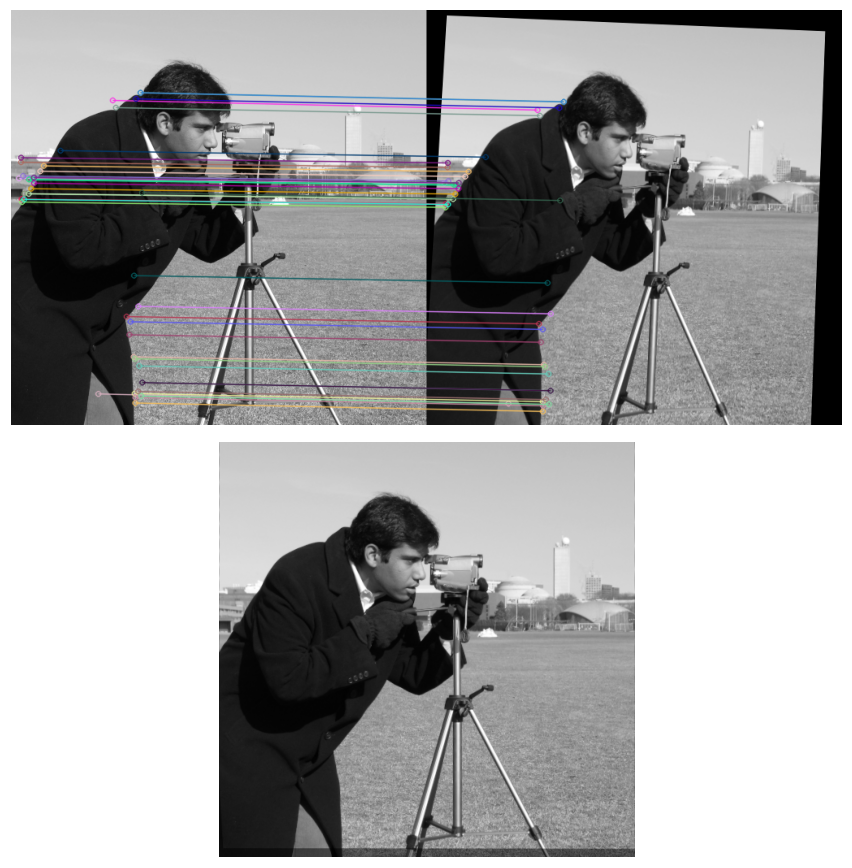

In [11]:
selected = [match for match, keep in zip(matches, inliers) if keep][:40]
matching_image = cv2.drawMatches(
    image, keypoints_a, warped, keypoints_b, selected, None, flags=2
)
aligned = cv2.warpPerspective(
    warped, np.linalg.inv(estimated), (image.shape[1], image.shape[0])
)
fig, axes = plt.subplots(2, 1, figsize=(10, 8))
axes[0].imshow(matching_image)
axes[1].imshow(0.5 * image + 0.5 * aligned, cmap="gray")
for axis in axes:
    axis.axis("off")
fig.tight_layout()
fig.savefig(output / "matching.png", dpi=140)
plt.show()
results = {
    "ratio_sweep": rows,
    "inlier_fraction": float(inliers.mean()),
    "corner_error_px": corner_error,
}

## Reading the result

A high inlier fraction is evidence of geometric agreement under the fitted model. The controlled corner error measures recovery against known geometry. A homography assumes a planar scene or camera rotation, so its interpretation changes for general 3D scenes.

Recorded run: At a ratio threshold of 0.7, 442 correspondences remained and 98.87% agreed with the known warp within three pixels. RANSAC recovered the transformed corners with a mean error of about 0.062 pixels. Raising the ratio to 0.9 increased match count while reducing controlled precision.

In [13]:
result_path = root / "results" / "02_sift_and_geometry.json"
result_path.write_text(json.dumps(results, indent=2, allow_nan=False) + "\n")
print(result_path.relative_to(root))

results/02_sift_and_geometry.json


## Next experiment

Import mountain1.png and mountain2.png and build a panorama with a translated canvas. Handle negative transformed coordinates before warping, and compare simple overlay with feathered blending.

## Sources

UniPd Computer Vision and Cognitive Systems: uploaded filtering, SIFT, BoW, MLP and CNN notebooks. [Lowe, 2004](https://www.cs.ubc.ca/~lowe/papers/ijcv04.pdf).

The implementations here were written for this project. Course notebooks and their saved weights are reference material; they are not redistributed.